# 07 — Modelo 3: Gradient Boosting

**Elaborado por:** Felipe Vivas

## Objetivo

Entrenar un **Gradient Boosting** con las mismas 11 variables y los mismos mapas que los dos
modelos anteriores, y medirlo en validación (2025). Es la familia de modelos que suele dar
mejores resultados en datos en forma de tabla, pero también la más fácil de sobreajustar: el
cuadernillo muestra ese riesgo con una **curva de log loss** y cómo se controla.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss

from src.config import PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import accuracy_interval, evaluate, temporal_split
from src.plotting import set_style, save_fig

set_style()
config = load_config()
FEATURES, TARGET, SEED = config["features"], config["target"], config["seed"]

dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")
train, val, test = temporal_split(dataset, config["split"])
train_fit = train[train["min_maps_played"] >= config["min_train_history"]]
X_train, y_train = train_fit[FEATURES], train_fit[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
print(f"Entrenamiento: {len(train_fit)} mapas | Validación: {len(val)} mapas | Variables: {len(FEATURES)}")

Entrenamiento: 5106 mapas | Validación: 1272 mapas | Variables: 11


## 1. Qué es Gradient Boosting y por qué se prueba

Igual que el Random Forest, combina muchos árboles de decisión. La diferencia está en *cómo*:

- **Random Forest:** entrena los árboles por separado y promedia sus respuestas.
- **Gradient Boosting:** entrena los árboles **en secuencia**. Cada árbol nuevo es pequeño y
  se dedica a corregir los errores que dejaron los anteriores. La predicción final es la suma
  de todos.

**Por qué se prueba:** en datos tabulares suele ser la familia con mejor desempeño. Además,
`HistGradientBoostingClassifier` **maneja los valores faltantes de forma nativa**: en cada
pregunta aprende hacia qué lado enviar los faltantes, sin necesidad de rellenarlos. Eso encaja
bien con este dataset, donde "no hay dato" tiene significado propio (por eso aquí no hay
`SimpleImputer`).

**Límite:** como cada árbol corrige a los anteriores, si se le deja seguir termina
"corrigiendo" hasta el ruido de los datos de entrenamiento. Es el modelo más propenso a
sobreajustarse y el que más depende de su configuración.

## 2. El riesgo: sobreajuste

Primero se entrena con la configuración por defecto de scikit-learn (100 árboles, tasa de
aprendizaje 0.1) y se mide en validación.

In [2]:
default_model = HistGradientBoostingClassifier(random_state=SEED).fit(X_train, y_train)
pd.Series(evaluate(y_val, default_model.predict_proba(X_val)[:, 1])).round(4)

accuracy    0.5401
roc_auc     0.5618
log_loss    0.7397
dtype: float64

Log loss de 0.74: peor que responder siempre 50 %. Para entender qué pasó se mira cómo
evoluciona el log loss **árbol por árbol**, en entrenamiento y en validación. Se compara con
una configuración más conservadora:

- `max_depth=3`: árboles poco profundos (cada uno combina como mucho 3 preguntas);
- `learning_rate=0.05`: cada árbol corrige solo un poco;
- `early_stopping=True`: **parada temprana**. El modelo aparta una parte del entrenamiento y
  deja de agregar árboles cuando esa parte deja de mejorar.

Árboles usados tras la parada temprana: 42


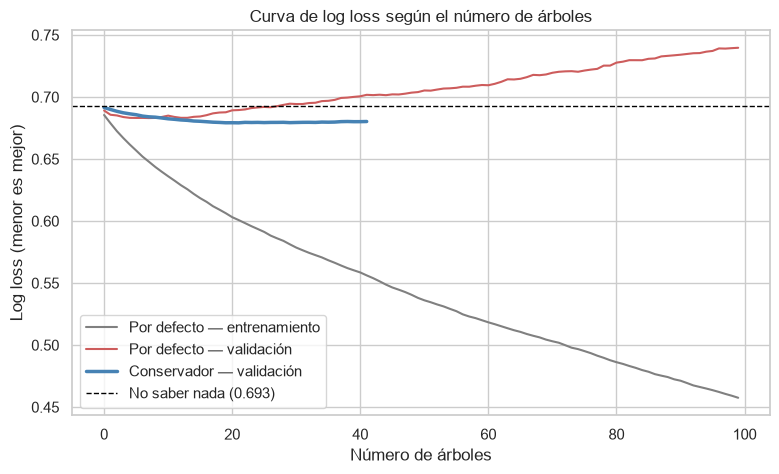

In [3]:
model = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, early_stopping=True,
                                       random_state=SEED).fit(X_train, y_train)
print("Árboles usados tras la parada temprana:", model.n_iter_)

def log_loss_por_arbol(modelo, X, y):
    """Log loss del modelo usando solo sus primeros 1, 2, 3… árboles."""
    return [log_loss(y, proba[:, 1]) for proba in modelo.staged_predict_proba(X)]

fig, ax = plt.subplots()
ax.plot(log_loss_por_arbol(default_model, X_train, y_train), label="Por defecto — entrenamiento", color="grey")
ax.plot(log_loss_por_arbol(default_model, X_val, y_val), label="Por defecto — validación", color="indianred")
ax.plot(log_loss_por_arbol(model, X_val, y_val), label="Conservador — validación", color="steelblue", linewidth=2.5)
ax.axhline(0.693, color="black", linestyle="--", linewidth=1, label="No saber nada (0.693)")
ax.set(title="Curva de log loss según el número de árboles", xlabel="Número de árboles",
       ylabel="Log loss (menor es mejor)")
ax.legend()
save_fig("07_curva_log_loss_arboles")
plt.show()

**Por qué este gráfico:** es una **curva de log loss** (una curva de aprendizaje): muestra cómo cambia el error del modelo a medida que se le agregan árboles. Es la forma más directa de *ver* el sobreajuste y de justificar por qué se usa una configuración conservadora.

**Cómo se lee:** el eje horizontal es el número de árboles que lleva el modelo; el vertical, su log loss (**más abajo es mejor**). La línea gris es el modelo por defecto medido en los mapas con los que entrena; la roja, el mismo modelo medido en validación; la azul, el modelo conservador en validación. La línea punteada es "no saber nada" (0.693).

**Qué muestra:**

- La línea gris baja sin parar: en entrenamiento, cada árbol nuevo "mejora" el modelo.
- La línea roja baja solo durante los primeros árboles y después **sube**, hasta quedar por encima de 0.693. El modelo dejó de aprender patrones generales y empezó a memorizar los mapas de entrenamiento. La separación creciente entre la gris y la roja *es* el sobreajuste.
- La línea azul baja despacio, se mantiene por debajo de 0.693 y se detiene sola: la parada temprana corta el entrenamiento antes de que empiece a memorizar.

## 3. Resultado del modelo

In [4]:
metrics = evaluate(y_val, model.predict_proba(X_val)[:, 1])
low, high = accuracy_interval(metrics["accuracy"], len(val))
print(f"Exactitud en validación: {metrics['accuracy']:.3f}  (IC 95 %: {low:.3f} – {high:.3f})")
pd.DataFrame({"Gradient Boosting": metrics}).T.to_csv(TABLES_DIR / "07_resultados_gradient_boosting.csv")
pd.Series(metrics).round(4)

Exactitud en validación: 0.575  (IC 95 %: 0.548 – 0.603)


accuracy    0.5755
roc_auc     0.5974
log_loss    0.6802
dtype: float64

## Conclusiones

1. **La configuración importa más que el modelo:** el mismo Gradient Boosting pasa de log
   loss 0.740 (por defecto, sobreajustado) a 0.680 (árboles pequeños, aprendizaje lento y
   parada temprana).
2. **La curva de log loss lo explica:** con la configuración por defecto, el log loss en
   validación empieza a subir después de los primeros árboles mientras en entrenamiento sigue
   bajando. Eso es sobreajuste.
3. **Resultado en validación (2025):** exactitud 0.575 (IC 95 %: 0.548–0.603), ROC-AUC 0.597 y
   log loss 0.680, usando 42 árboles.
4. Es el mejor log loss de los tres modelos (logística 0.688, Random Forest 0.688), aunque
   las diferencias son pequeñas.

**Siguiente paso (cuadernillo 08):** comparar los tres modelos contra líneas base simples,
elegir uno, ajustarlo y evaluarlo en el conjunto de prueba (2026).